# Calculadora cuántica

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tanmacre1998-art/CC_A_Complejo/blob/main/notebooks/calculadora_cuantica.ipynb)

**Análisis Complejo** — José Mauricio Naged Lancheros, Manuel Armando Jerez Gamboa, Miguel Kratzer Giraldo,
Andrés Felipe Ramírez Sarmiento

En este Notebook evidenciamos cómo hicimos una calculadora que suma y multiplica usando circuitos cuánticos en
Qiskit. Principalmente hicimos tres cosas:

* una suma con la **Transformada Cuántica de Fourier** (sumador de Draper),
* una suma "clásica" con compuertas reversibles (sumador de Cuccaro), para comparar,
* una multiplicación, también con la QFT.

El código está en la carpeta `qcalc/` del repositorio; aquí lo vamos usando y explicando.

## 0. Instalación


In [ ]:
# En Colab hay que instalar Qiskit y descargar el repositorio. En el computador no hace falta pero igualmente se puede hacer con powershell (en windows)

REPO_URL = "https://github.com/tanmacre1998-art/CC_A_Complejo.git"

import sys, os
try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install -q qiskit qiskit-aer pylatexenc
    if not os.path.exists("CC_A_Complejo"):
        !git clone -q $REPO_URL
    os.chdir("CC_A_Complejo")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import qiskit, qiskit_aer
print("Qiskit", qiskit.__version__, "| Aer", qiskit_aer.__version__)

Qiskit 2.6.2 | Aer 0.18.4


In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_histogram

from qcalc import (QuantumCalculator, build_addition, build_multiplication, circuit_metrics,
                   cuccaro_adder, draper_adder, qft, qft_multiplier)

## 1. La idea general es que en el mundo cuántico la trazabilidad es lo más importante, o sea hacer las cosas reversibles


Lo primero que nos encontramos es que no se puede sumar "normal". Si tengo 8, no sé si vino de 5 + 3 o de 6 + 2,
entonces la suma pierde información. Pero las operaciones cuánticas son matrices unitarias y siempre se pueden
deshacer. La solución es guardar uno de los números y escribir el resultado en el otro:

$$|a\rangle\,|b\rangle \;\longrightarrow\; |a\rangle\,|a+b\rangle$$

Cada número se guarda en binario, un bit por qubit. **Ojo** (esto nos hizo perder bastante tiempo): en Qiskit el
qubit 0 es el bit **menos** significativo, y cuando imprime los resultados los muestra al revés.

## 2. Y pues también tiene cosas de del curso de análisis complejo: la TRansformada de Fourier CUántica (QFT) y las raíces de la unidad

La Transformada Cuántica de Fourier es la misma transformada discreta de Fourier de siempre, aplicada a las
amplitudes. Si $\omega = e^{2\pi i/N}$ es una raíz $N$-ésima de la unidad:

$$\mathrm{QFT}\,|x\rangle = \frac{1}{\sqrt{N}}\sum_{y=0}^{N-1} \omega^{xy}\,|y\rangle$$

O sea, después de la QFT **el número $x$ queda escondido en las fases** $\omega^{xy}$, que son puntos del círculo
unitario. Y aquí está el truco: para sumarle $a$ a $x$ no hay que hacer nada raro, solo multiplicar cada amplitud
por $\omega^{ay}$, porque

$$\omega^{xy}\cdot\omega^{ay} = \omega^{(x+a)y}.$$

Multiplicar por $e^{i\theta}$ es **girar** en el plano complejo. Entonces **sumar = rotar fases**. Lo
comprobamos con $N = 16$: aplicamos la QFT a $|5\rangle$ y vemos que las amplitudes (multiplicadas por $\sqrt{16}$)
son justo las potencias $\omega^{5y}$. Después de sumar 2 quedan como $\omega^{7y}$.

¿Las amplitudes de QFT|5> son w^(5y)? True
¿Multiplicar por w^(2y) da QFT|7>?    True


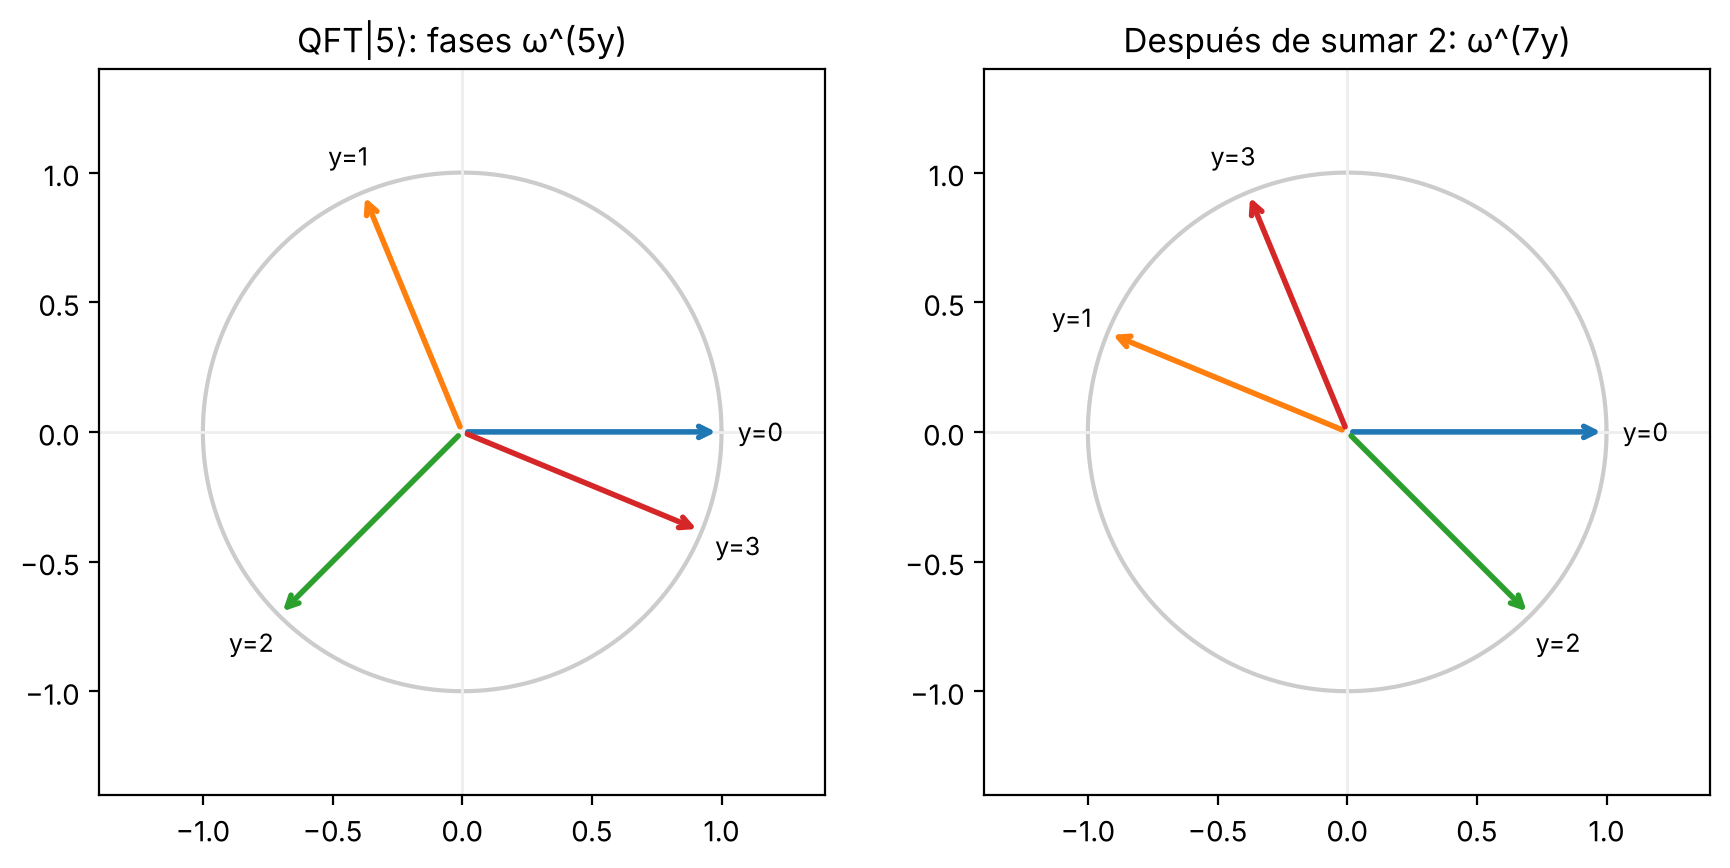

In [ ]:
N, x, a = 16, 5, 2
w = np.exp(2j * np.pi / N)

amp_x = Statevector.from_int(x, N).evolve(qft(4)).data * np.sqrt(N)
amp_suma = Statevector.from_int(x + a, N).evolve(qft(4)).data * np.sqrt(N)
print("¿Las amplitudes de QFT|5> son w^(5y)?", np.allclose(amp_x, w ** (x * np.arange(N))))
print("¿Multiplicar por w^(2y) da QFT|7>?   ", np.allclose(amp_x * w ** (a * np.arange(N)), amp_suma))

fig, axs = plt.subplots(1, 2, figsize=(9, 4.3))
t = np.linspace(0, 2 * np.pi, 200)
for ax, amps, titulo in [(axs[0], amp_x, "QFT|5⟩: fases ω^(5y)"), (axs[1], amp_suma, "Después de sumar 2: ω^(7y)")]:
    ax.plot(np.cos(t), np.sin(t), color="#cccccc")
    for y in range(4):  # solo las primeras 4 para que se vea
        z = amps[y]
        ax.annotate("", xy=(z.real, z.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=f"C{y}", lw=2))
        ax.text(1.15 * z.real, 1.15 * z.imag, f"y={y}", ha="center", va="center", fontsize=9)
    ax.set_aspect("equal"); ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
    ax.axhline(0, color="#eeeeee", lw=1); ax.axvline(0, color="#eeeeee", lw=1)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()

Cada flecha gira $2y$ "pasos" de $2\pi/16$. Esto fue lo que nos hizo entender de verdad por qué el sumador de
Draper funciona.

### El circuito de la QFT

En un circuito, la QFT se arma con compuertas Hadamard y rotaciones de fase controladas. La programamos a mano (auqnue hay que ser honestos, se las pedimos a Claude porque nos pereció muy complejo la integración de todo el circuito) y luego la
comparamos con la que trae Qiskit. Al principio **no nos daba igual**: nos faltaban los SWAP del final, que invierten el
orden de los qubits y pues CLaude tampoco lo detectó.

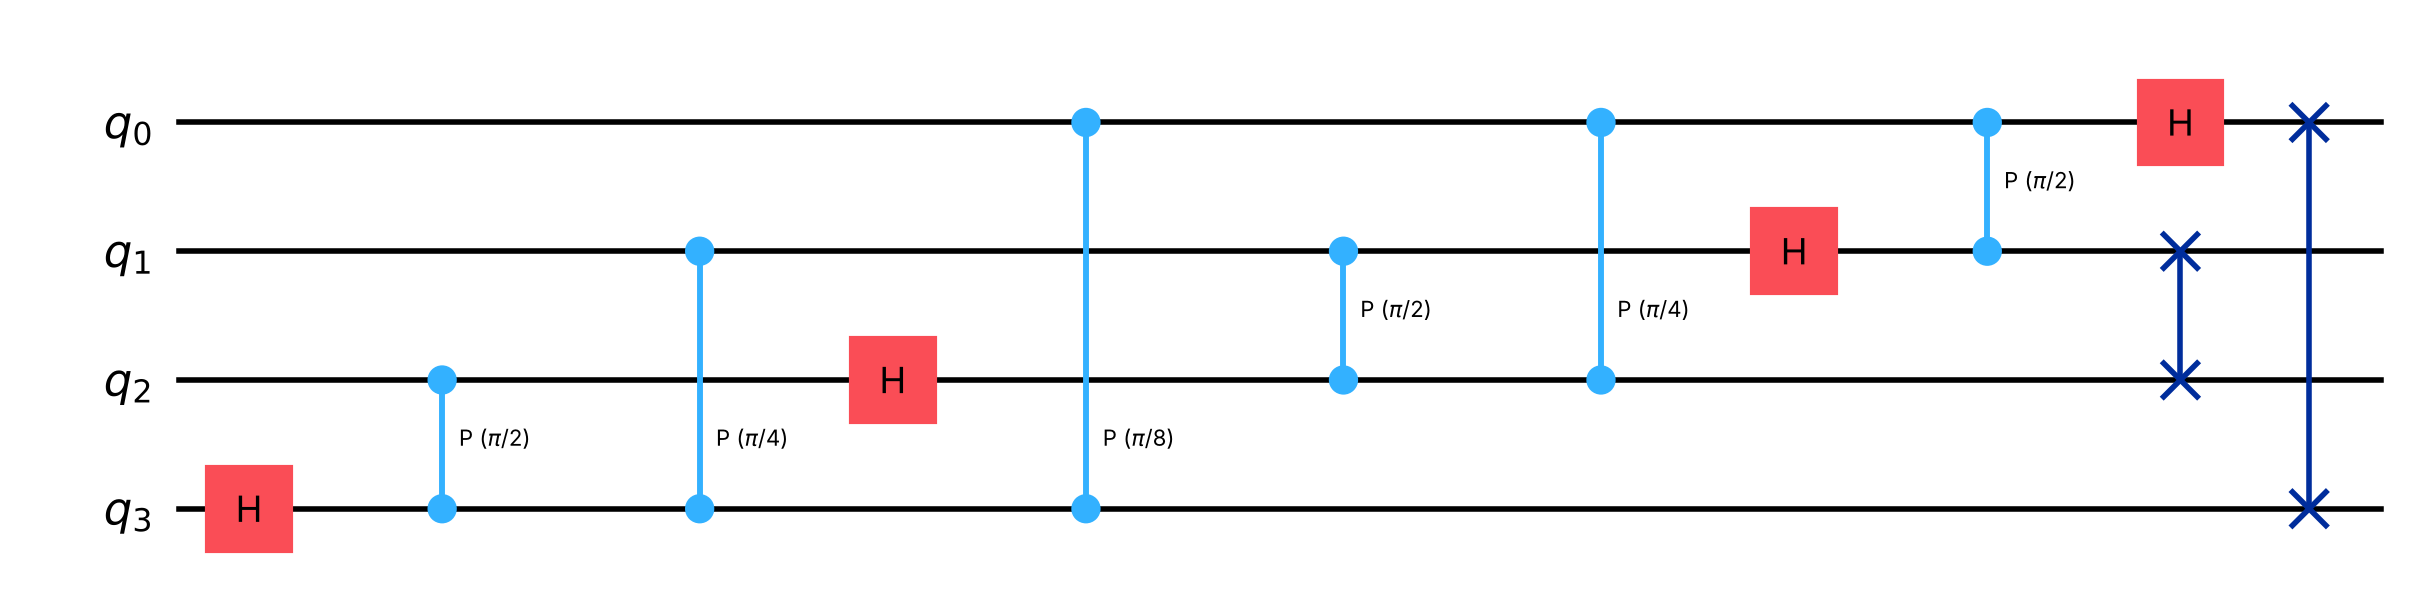

✔ Nuestra QFT da exactamente la misma matriz que la de Qiskit (n = 1 a 6)


In [ ]:
display(qft(4).draw("mpl"))
for n in range(1, 7):
    assert Operator(qft(n)).equiv(Operator(QFTGate(n)))
print("✔ Nuestra QFT da exactamente la misma matriz que la de Qiskit (n = 1 a 6)")

## 3. Suma con la QFT (sumador de Draper)

1. Se aplica la QFT al registro $b$. Le damos un qubit extra para el acarreo (sin él, 7 + 1 nos daba 0).
2. Para sumar $a$, cada bit $a_i$ controla rotaciones de ángulo $2\pi\cdot 2^{i+k}/2^L$ sobre el qubit $k$ de $b$.
   Es exactamente el "multiplicar por $\omega^{ay}$" de arriba, pero separado bit por bit.
3. Se aplica la QFT inversa y en $b$ queda $a+b$.

Para ahorrar compuertas quitamos los SWAP de la QFT, pero entonces hay que leer los qubits en orden inverso
(eso también daña la suma).

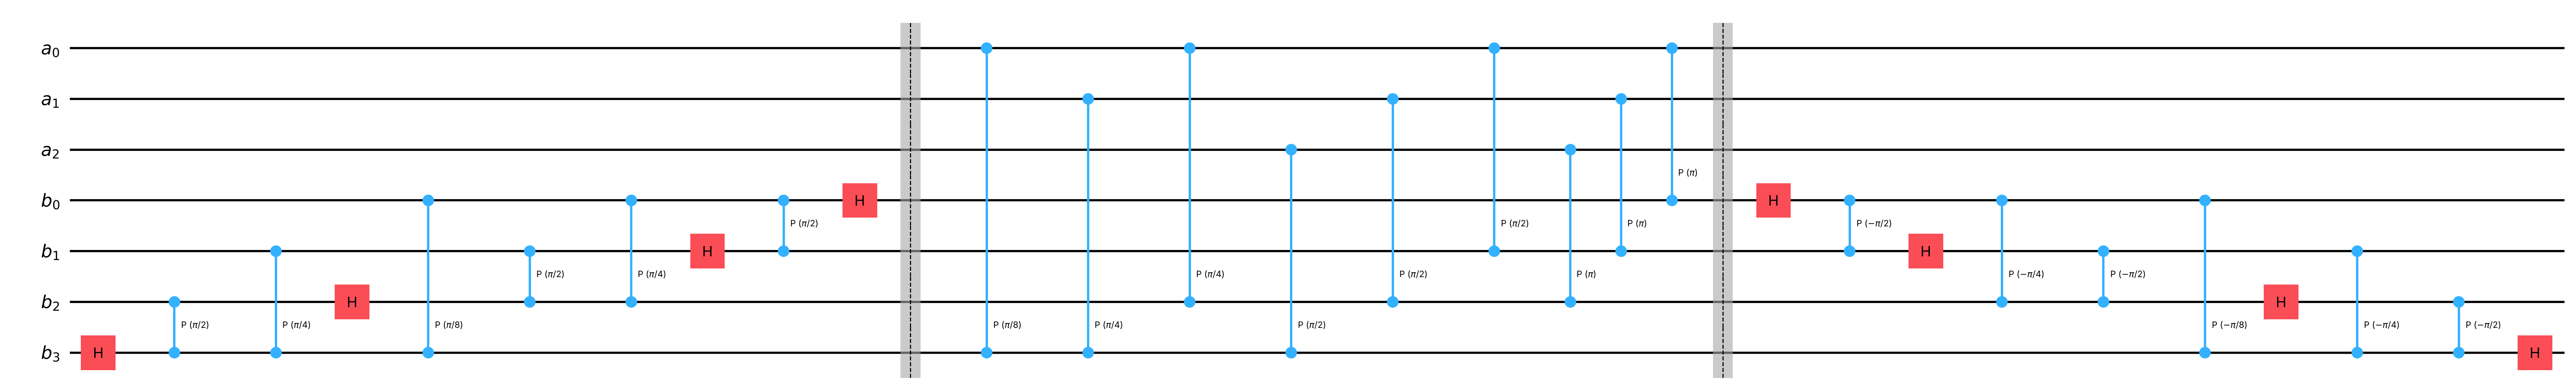

In [ ]:
display(draper_adder(3).draw("mpl", fold=-1))

El circuito completo para **5 + 3**: las compuertas X ponen los números, después va el sumador y al final se mide.

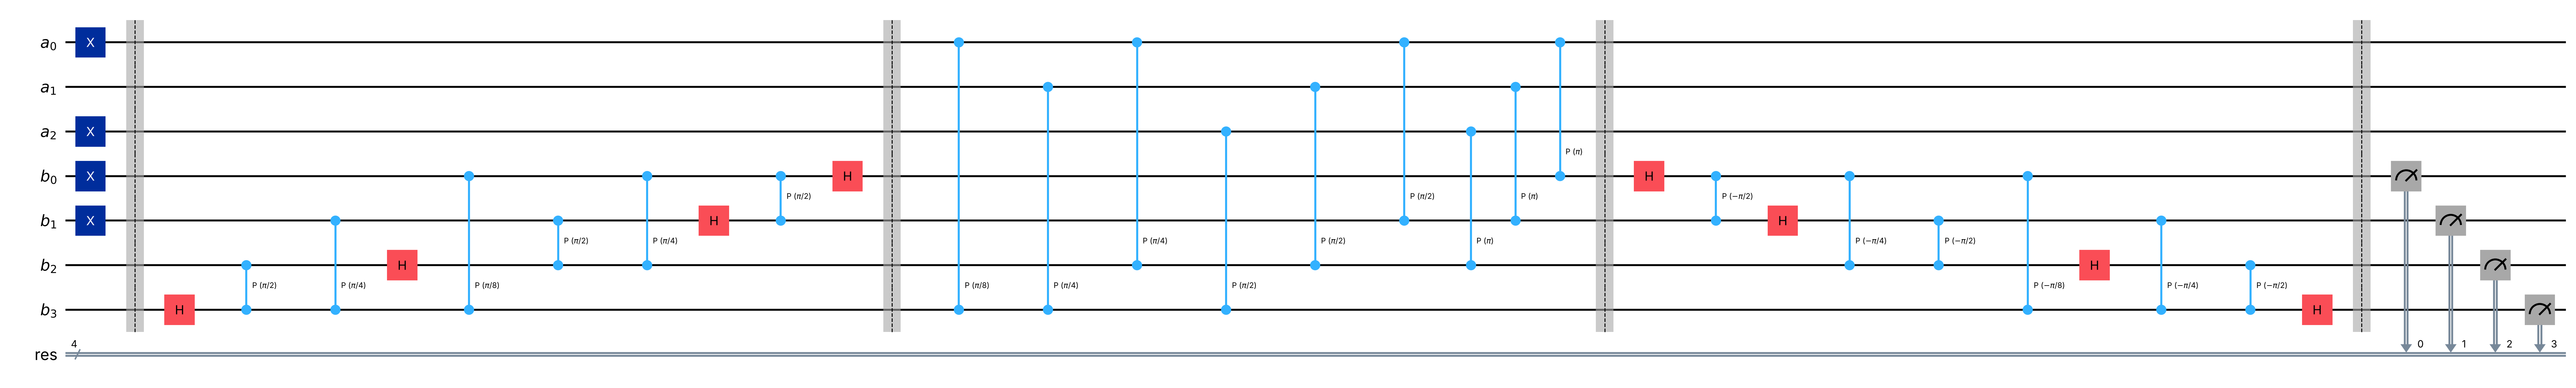

5 + 3 = 8  ✔  (binario 1000, P(correcto)=1.000, 7 qubits, profundidad 67)


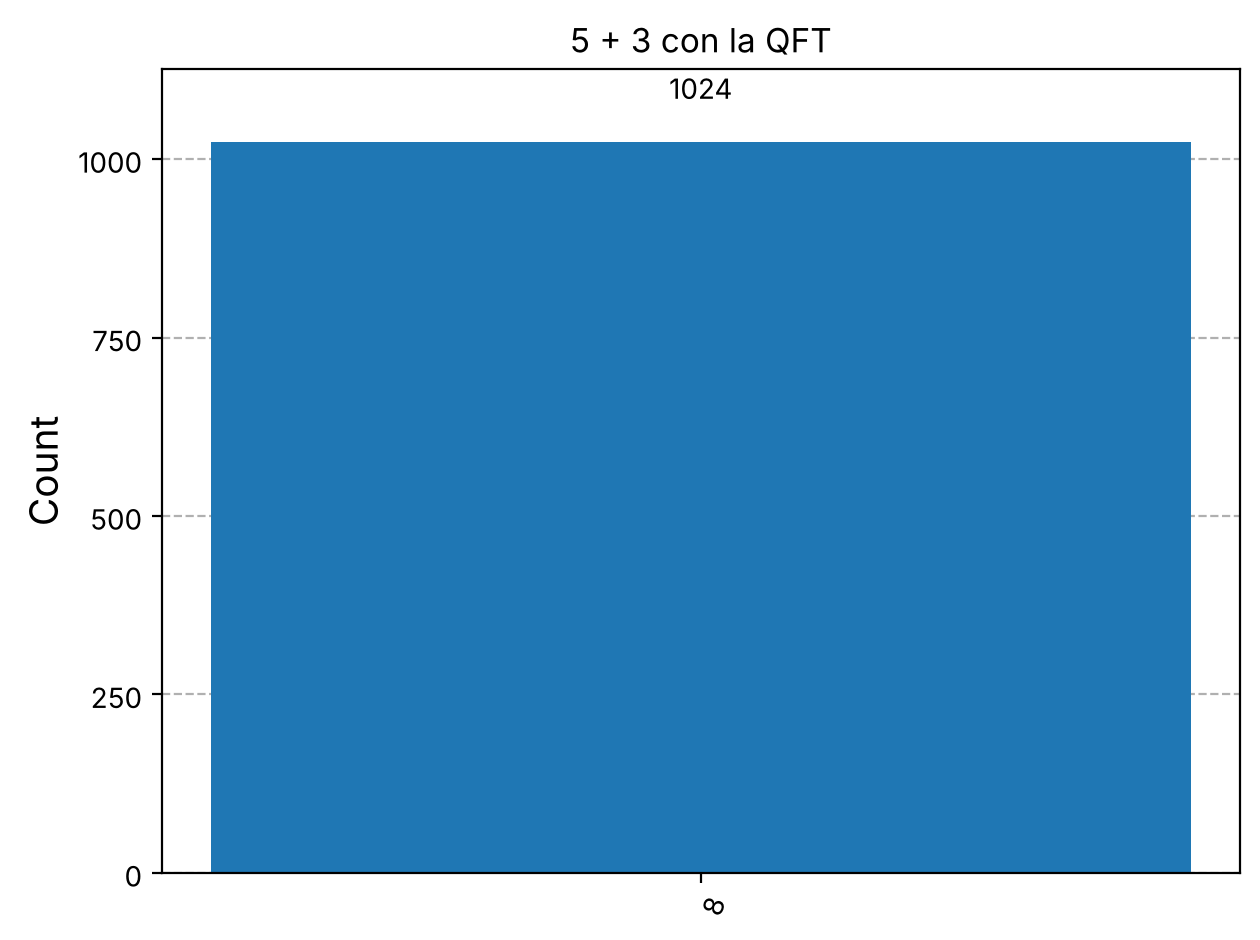

In [ ]:
qc, core = build_addition(5, 3, method="qft", n=3)
display(qc.draw("mpl", fold=-1))

calc = QuantumCalculator(shots=1024)
r = calc.add(5, 3)
print(r)
plot_histogram(r.counts, title="5 + 3 con la QFT")

Para estar seguros probamos **todas** las parejas de números de 3 bits (64 casos):

In [ ]:
def ejecutar_exacto(circuito, indice):
    sv = Statevector.from_int(indice, 2 ** circuito.num_qubits).evolve(circuito)
    return max(range(len(sv)), key=lambda i: abs(sv[i]))

n = 3
circ = draper_adder(n)
errores = 0
for a, b in itertools.product(range(2 ** n), repeat=2):
    salida = ejecutar_exacto(circ, a | (b << n))
    errores += (salida >> n) != a + b
print(f"Draper, n={n}: {2**(2*n)} casos, {errores} errores")

Draper, n=3: 64 casos, 0 errores


## 4. Suma clásica (Cuccaro)

Esta la hicimos para comparar. Es como el sumador de acarreo de electrónica digital, pero con compuertas que se
pueden deshacer: CNOT y Toffoli (un AND reversible). Tiene dos bloques:

* **MAJ:** calcula el acarreo y lo guarda temporalmente.
* **UMA:** deshace el MAJ y deja el bit de la suma.

El acarreo sube con los MAJ y baja con los UMA. Nos costó entender el orden de las compuertas; si se pone mal,
quedan qubits con "basura" al final.

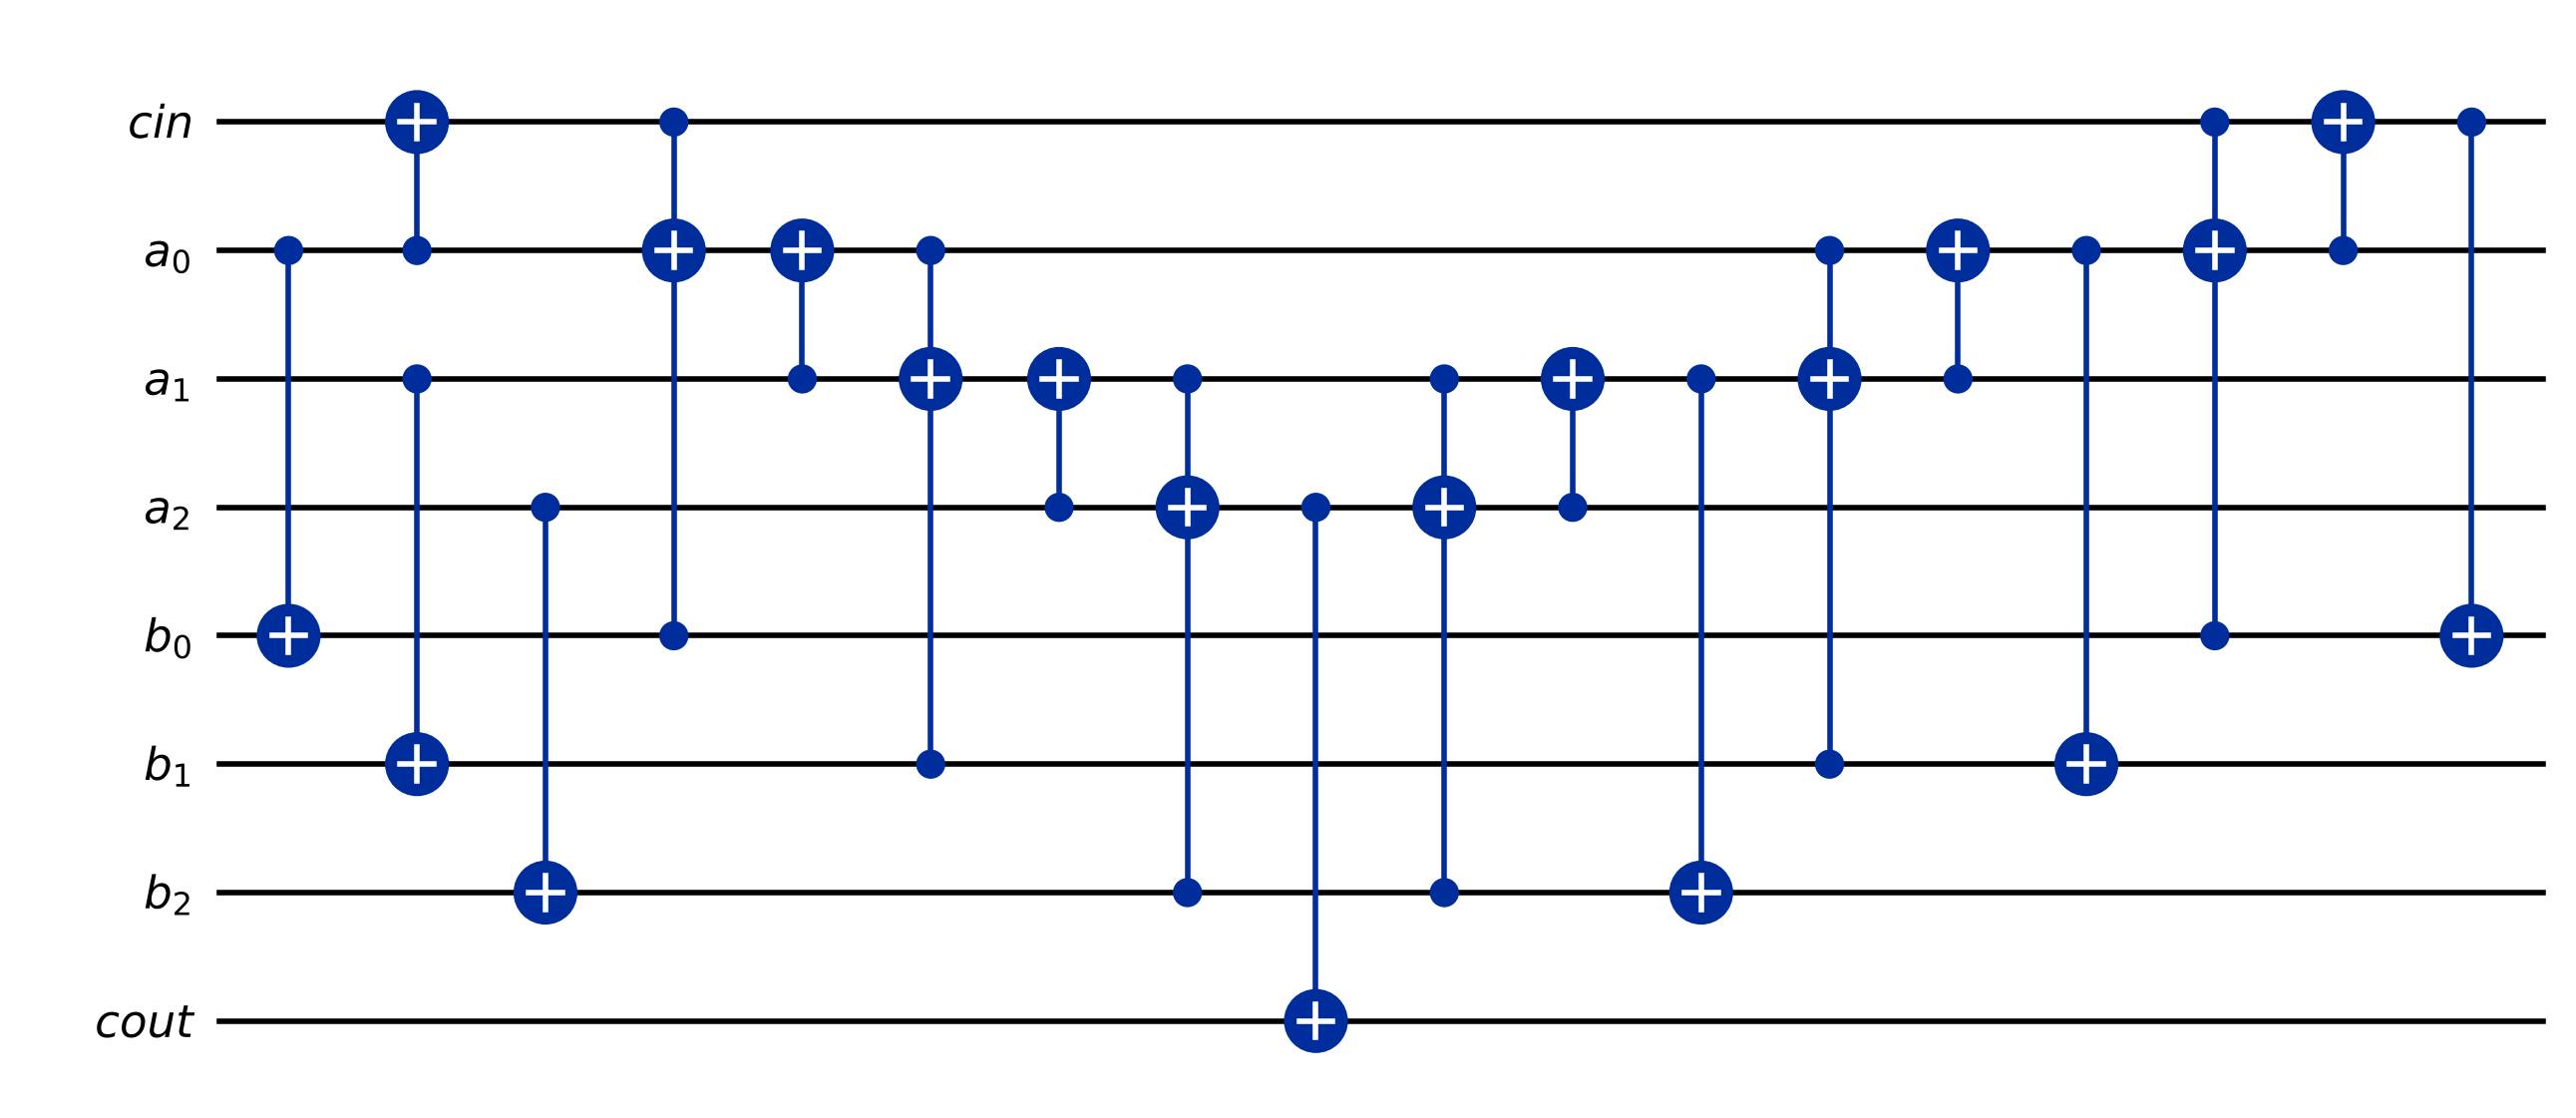

5 + 3 = 8  ✔  (binario 1000, P(correcto)=1.000, 8 qubits, profundidad 89)
Cuccaro, n=3: 64 casos, 0 errores


In [ ]:
display(cuccaro_adder(3).draw("mpl", fold=-1))
r = calc.add(5, 3, method="ripple")
print(r)

n = 3
circ = cuccaro_adder(n)
errores = 0
for a, b in itertools.product(range(2 ** n), repeat=2):
    out = ejecutar_exacto(circ, (a << 1) | (b << (n + 1)))
    s, carry = (out >> (n + 1)) & (2 ** n - 1), out >> (2 * n + 1)
    errores += s + (carry << n) != a + b
print(f"Cuccaro, n={n}: {2**(2*n)} casos, {errores} errores")

## 5. Multiplicación

Multiplicamos como a mano: desplazar y sumar.

$$a\cdot b = \sum_{i,j} a_i\,b_j\,2^{i+j}$$

Ponemos el registro del resultado en el espacio de Fourier y, para cada par de bits $(a_i, b_j)$, sumamos $2^{i+j}$
con una rotación que solo se aplica si **los dos** bits valen 1 (una compuerta de fase con dos controles). Al final,
QFT inversa. Lo sacamos del artículo de Ruiz-Pérez y García-Escartín (2017).

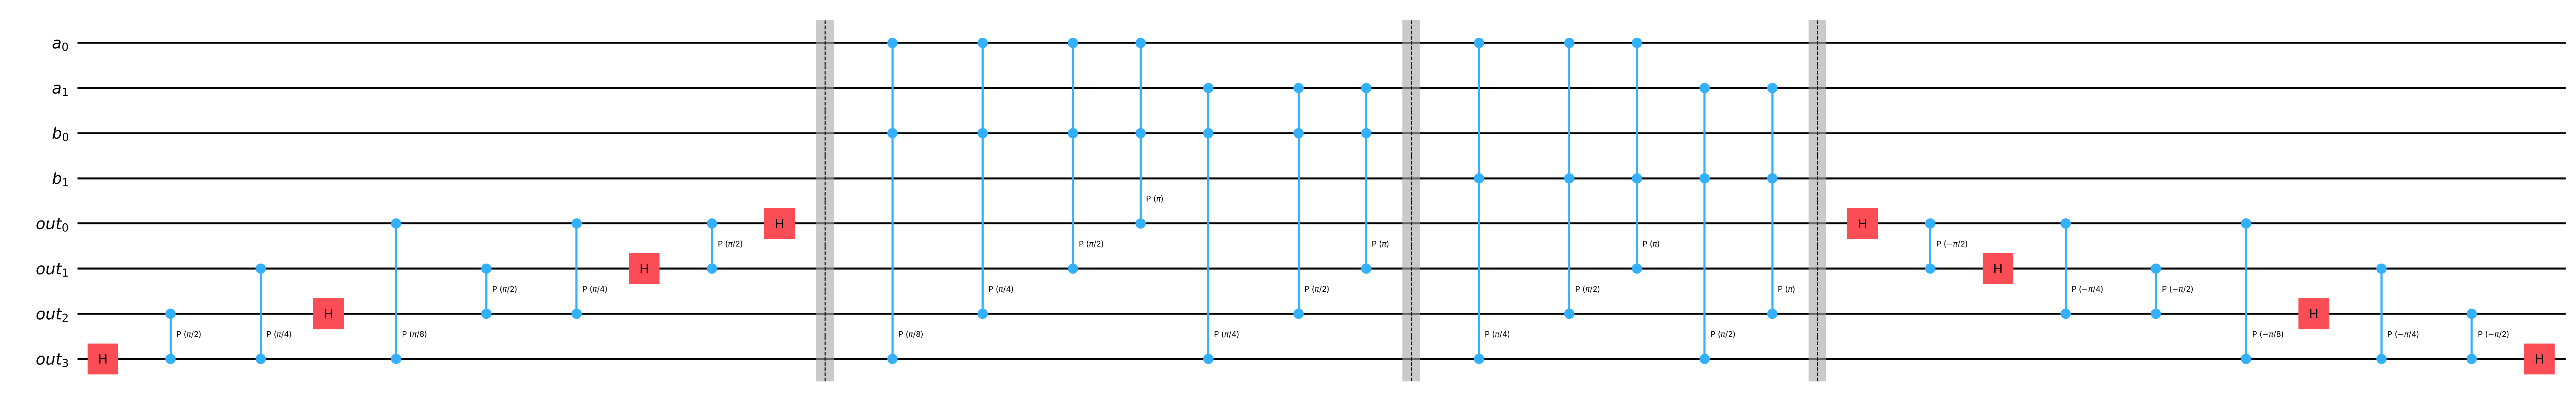

3 × 3 = 9  ✔  (binario 1001, P(correcto)=1.000, 8 qubits, profundidad 188)
6 × 7 = 42  ✔  (binario 101010, P(correcto)=1.000, 12 qubits, profundidad 496)


53 × 4 = 212  ✔  (binario 11010100, P(correcto)=1.000, 18 qubits, profundidad 1273)
15 × 15 = 225  ✔  (binario 11100001, P(correcto)=1.000, 16 qubits, profundidad 1038)


In [ ]:
display(qft_multiplier(2, 2).draw("mpl", fold=-1))
for a, b in [(3, 3), (6, 7), (53, 4), (15, 15)]:
    print(calc.multiply(a, b))

In [ ]:
errores, casos = 0, 0
for n, m in [(2, 2), (3, 3)]:
    circ = qft_multiplier(n, m)
    for a in range(2 ** n):
        for b in range(2 ** m):
            out = ejecutar_exacto(circ, a | (b << n))
            errores += (out >> (n + m)) != a * b
            casos += 1
print(f"Multiplicación (2x2 y 3x3 bits): {casos} casos, {errores} errores")

Multiplicación (2x2 y 3x3 bits): 80 casos, 0 errores


Probamos con números de 8 bits y el computador se quedó pegado: eran 32 qubits, y simular eso necesita
muchísima memoria. Por eso la calculadora tiene un límite de 28 qubits.

## 6. La calculadora

Juntamos todo en una clase `QuantumCalculator`. Le escribes la operación, arma el circuito con los qubits
necesarios, lo simula 1024 veces y devuelve el resultado que más salió.

In [ ]:
for expr in ["12 + 30", "255 + 1", "320 + 150", "9 * 9", "123 * 45"]:
    print(calc.evaluate(expr))

12 + 30 = 42  ✔  (binario 101010, P(correcto)=1.000, 11 qubits, profundidad 107)
255 + 1 = 256  ✔  (binario 100000000, P(correcto)=1.000, 17 qubits, profundidad 167)


320 + 150 = 470  ✔  (binario 111010110, P(correcto)=1.000, 19 qubits, profundidad 187)
9 × 9 = 81  ✔  (binario 1010001, P(correcto)=1.000, 16 qubits, profundidad 1038)


123 × 45 = 5535  ✔  (binario 1010110011111, P(correcto)=1.000, 26 qubits, profundidad 3866)


In [ ]:
# Para probar sus propias operaciones, quiten el # de las dos líneas:
# expr = input("Operación (ej. 7 * 6): ")
# print(calc.evaluate(expr))

## 7. ¿Cuánto "cuesta" cada circuito?

Contamos qubits, profundidad (cuántos pasos seguidos tiene el circuito) y compuertas CNOT, que son las que más
errores tienen en un computador cuántico real.

In [ ]:
print(f"{'circuito':<24}{'n':>3}{'qubits':>8}{'profund.':>10}{'CNOT':>7}")
for n in [2, 4, 6, 8]:
    for nombre, c in [("Draper (QFT)", draper_adder(n)), ("Cuccaro", cuccaro_adder(n))]:
        m = circuit_metrics(c)
        print(f"{nombre:<24}{n:>3}{m['qubits']:>8}{m['profundidad']:>10}{m['cx']:>7}")
for n in [2, 3, 4]:
    m = circuit_metrics(qft_multiplier(n, n))
    print(f"{'Multiplicación':<24}{n:>3}{m['qubits']:>8}{m['profundidad']:>10}{m['cx']:>7}")

circuito                  n  qubits  profund.   CNOT
Draper (QFT)              2       5        47     22
Cuccaro                   2       6        60     33
Draper (QFT)              4       9        87     68
Cuccaro                   4      10       118     65
Draper (QFT)              6      13       127    138
Cuccaro                   6      14       176     97
Draper (QFT)              8      17       167    232
Cuccaro                   8      18       234    129
Multiplicación            2       8       188     96
Multiplicación            3      12       496    276
Multiplicación            4      16      1038    592


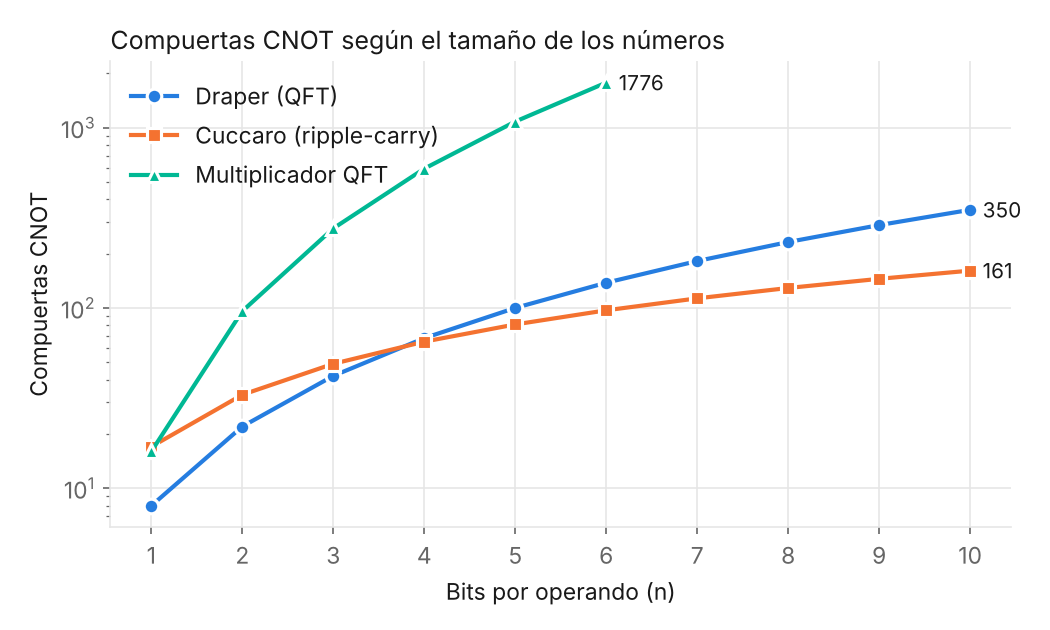

In [ ]:
from IPython.display import Image
display(Image("figuras/recursos_cx.png", width=650))

Lo que vimos:

* Con números pequeños la suma con QFT gasta menos CNOT, pero desde 4 bits la de Cuccaro gasta menos. La de QFT
  crece más o menos como $n^2$ y la de Cuccaro como $16n$.
* La de QFT es menos "profunda", porque varias rotaciones se pueden hacer al mismo tiempo.
* La multiplicación es muchísimo más cara: con 6 bits ya son 1776 CNOT.

## 8. Algo curioso: sumar en superposición

Si ponemos $a$ en superposición (con Hadamards), el mismo circuito suma 5 a **todos** los valores de $a$ a la vez.
Pero cuando medimos solo sale **uno**, al azar. Entonces no es que se puedan hacer 8 sumas gratis; para sacarle
provecho haría falta un algoritmo más complicado, como el de Shor.

In [ ]:
from qiskit import ClassicalRegister, QuantumCircuit, transpile
from qiskit_aer import AerSimulator

n, b = 3, 5
core = draper_adder(n)
ra, rb = core.qregs
qc = QuantumCircuit(ra, rb, ClassicalRegister(n, "ma"), ClassicalRegister(n + 1, "mb"))
qc.h(ra)
for i in range(n + 1):
    if (b >> i) & 1:
        qc.x(rb[i])
qc.compose(core, inplace=True)
qc.measure(ra, qc.cregs[0]); qc.measure(rb, qc.cregs[1])

sim = AerSimulator(seed_simulator=3)
counts = sim.run(transpile(qc, sim), shots=4000).result().get_counts()
pares = sorted((int(k.split()[1], 2), int(k.split()[0], 2), c) for k, c in counts.items())
for a, s, c in pares:
    print(f"a = {a}  ->  a+5 medido = {s:2d}  {'✔' if s == a + b else '✘'}   ({c} veces)")

a = 0  ->  a+5 medido =  5  ✔   (484 veces)
a = 1  ->  a+5 medido =  6  ✔   (499 veces)
a = 2  ->  a+5 medido =  7  ✔   (528 veces)
a = 3  ->  a+5 medido =  8  ✔   (512 veces)
a = 4  ->  a+5 medido =  9  ✔   (488 veces)
a = 5  ->  a+5 medido = 10  ✔   (488 veces)
a = 6  ->  a+5 medido = 11  ✔   (493 veces)
a = 7  ->  a+5 medido = 12  ✔   (508 veces)


## 9. ¿Y en un computador cuántico de verdad? (ruido)

Los computadores cuánticos reales se equivocan en cada compuerta. Lo simulamos con ruido "depolarizante": cada
CNOT falla con probabilidad $p$ (y las de un qubit con $p/10$). Esta parte se demoró bastante en correr.

In [ ]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

def modelo_ruido(p2):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p2 / 10, 1), ["sx", "x", "rz"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    return nm

print(f"{'error CNOT':>11} | {'QFT 3+5':>8} | {'Cuccaro 3+5':>11} | {'Mult 3x5':>9}")
for p in [0.001, 0.005, 0.01]:
    noisy = QuantumCalculator(shots=2000, noise_model=modelo_ruido(p))
    d = noisy.add(3, 5).success_probability
    c = noisy.add(3, 5, method="ripple").success_probability
    m = noisy.multiply(3, 5).success_probability
    print(f"{p*100:>10.1f}% | {d:>8.3f} | {c:>11.3f} | {m:>9.3f}")

 error CNOT |  QFT 3+5 | Cuccaro 3+5 |  Mult 3x5


       0.1% |    0.965 |       0.968 |     0.872


       0.5% |    0.832 |       0.847 |     0.536


       1.0% |    0.705 |       0.722 |     0.290


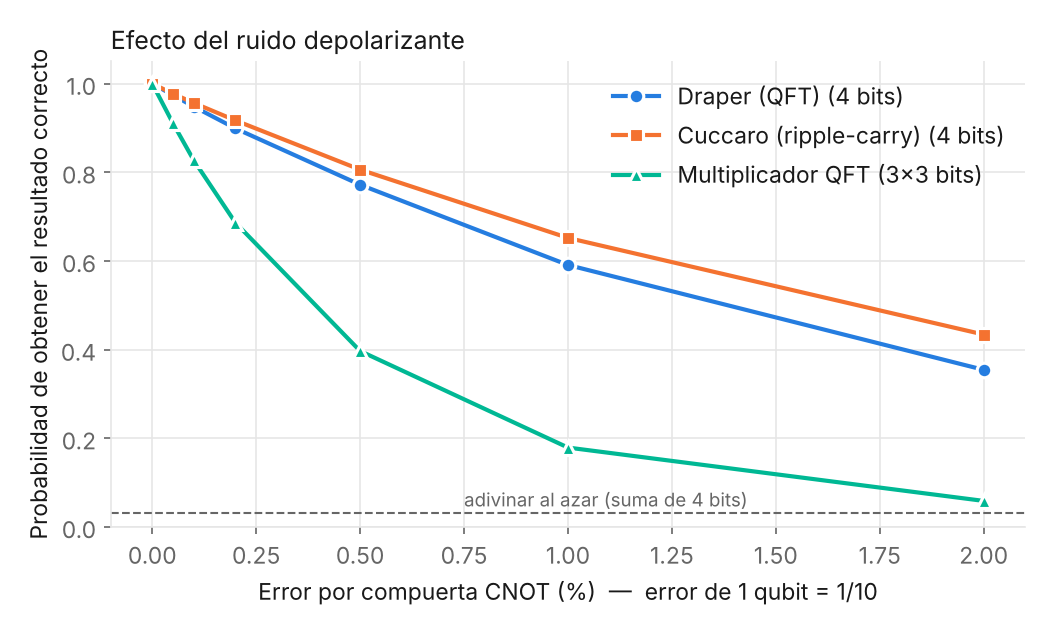

In [ ]:
display(Image("figuras/ruido.png", width=650))

Con 1 % de error la suma todavía acierta la mayoría de las veces, pero la multiplicación casi nunca (alrededor
del 18 % con números de 3 bits). Mientras más compuertas, más se acumula el error.

## 10. Correrlo aquí vs. en un computador cuántico real

Todo lo anterior corrió en un **simulador**: un programa en un computador normal que hace las cuentas que haría un
computador cuántico. Al final mandamos el mismo circuito, **5 + 3 con el sumador de Cuccaro**
(`qasm/suma_5mas3_cuccaro.qasm`), a un computador cuántico de verdad: **ibm_kingston**, de IBM, con 156 qubits.
En esta sección comparamos las dos cosas.

| | En nuestro computador (PowerShell / Colab) | En ibm_kingston (IBM) |
|---|---|---|
| **Qué es** | Un simulador (`AerSimulator`) que corre en la CPU | Un chip superconductor real, enfriado casi al cero absoluto |
| **Cómo "guarda" los qubits** | Un vector de $2^n$ números complejos en la RAM | Qubits físicos de verdad |
| **Compuertas** | Las que escribimos (X, CNOT, Toffoli…) | Solo las nativas del chip: $\sqrt{X}$, $R_Z$, $X$ y CZ |
| **Conexiones** | Cualquier qubit con cualquiera | Cada qubit solo se conecta con sus vecinos |
| **Errores** | Ninguno (a menos que simulemos ruido) | Cada compuerta y cada medición se pueden equivocar |
| **Tiempo** | Instantáneo | Fila + ejecución (a nosotros nos tomó unos segundos) |
| **Resultado de 5 + 3** | 8 el 100 % de las veces | 8 el 74,8 % de las veces |

### ¿Qué pasa en cada caso?

**En PowerShell o Colab:**
1. Qiskit arma el circuito.
2. El simulador multiplica el vector de estado por la matriz de cada compuerta.
3. Al final calcula las probabilidades $|amplitud|^2$ y "lanza los dados" 1024 veces.

**En IBM:**
1. El circuito se envía por internet (como OpenQASM) a la nube de IBM.
2. IBM lo **traduce** (*transpila*) a las compuertas nativas del chip y escoge qué qubits físicos usar.
3. El trabajo espera en la fila.
4. El chip ejecuta el circuito con pulsos de microondas y mide los qubits. Esto se repite 1024 veces.
5. Los resultados vuelven y aparecen en *Workloads*.

Es el mismo circuito; lo que cambia es **dónde** y **cómo** se ejecuta.

Compuertas del circuito original: {'cx': 13, 'ccx': 6, 'x': 4, 'measure': 4, 'barrier': 2}


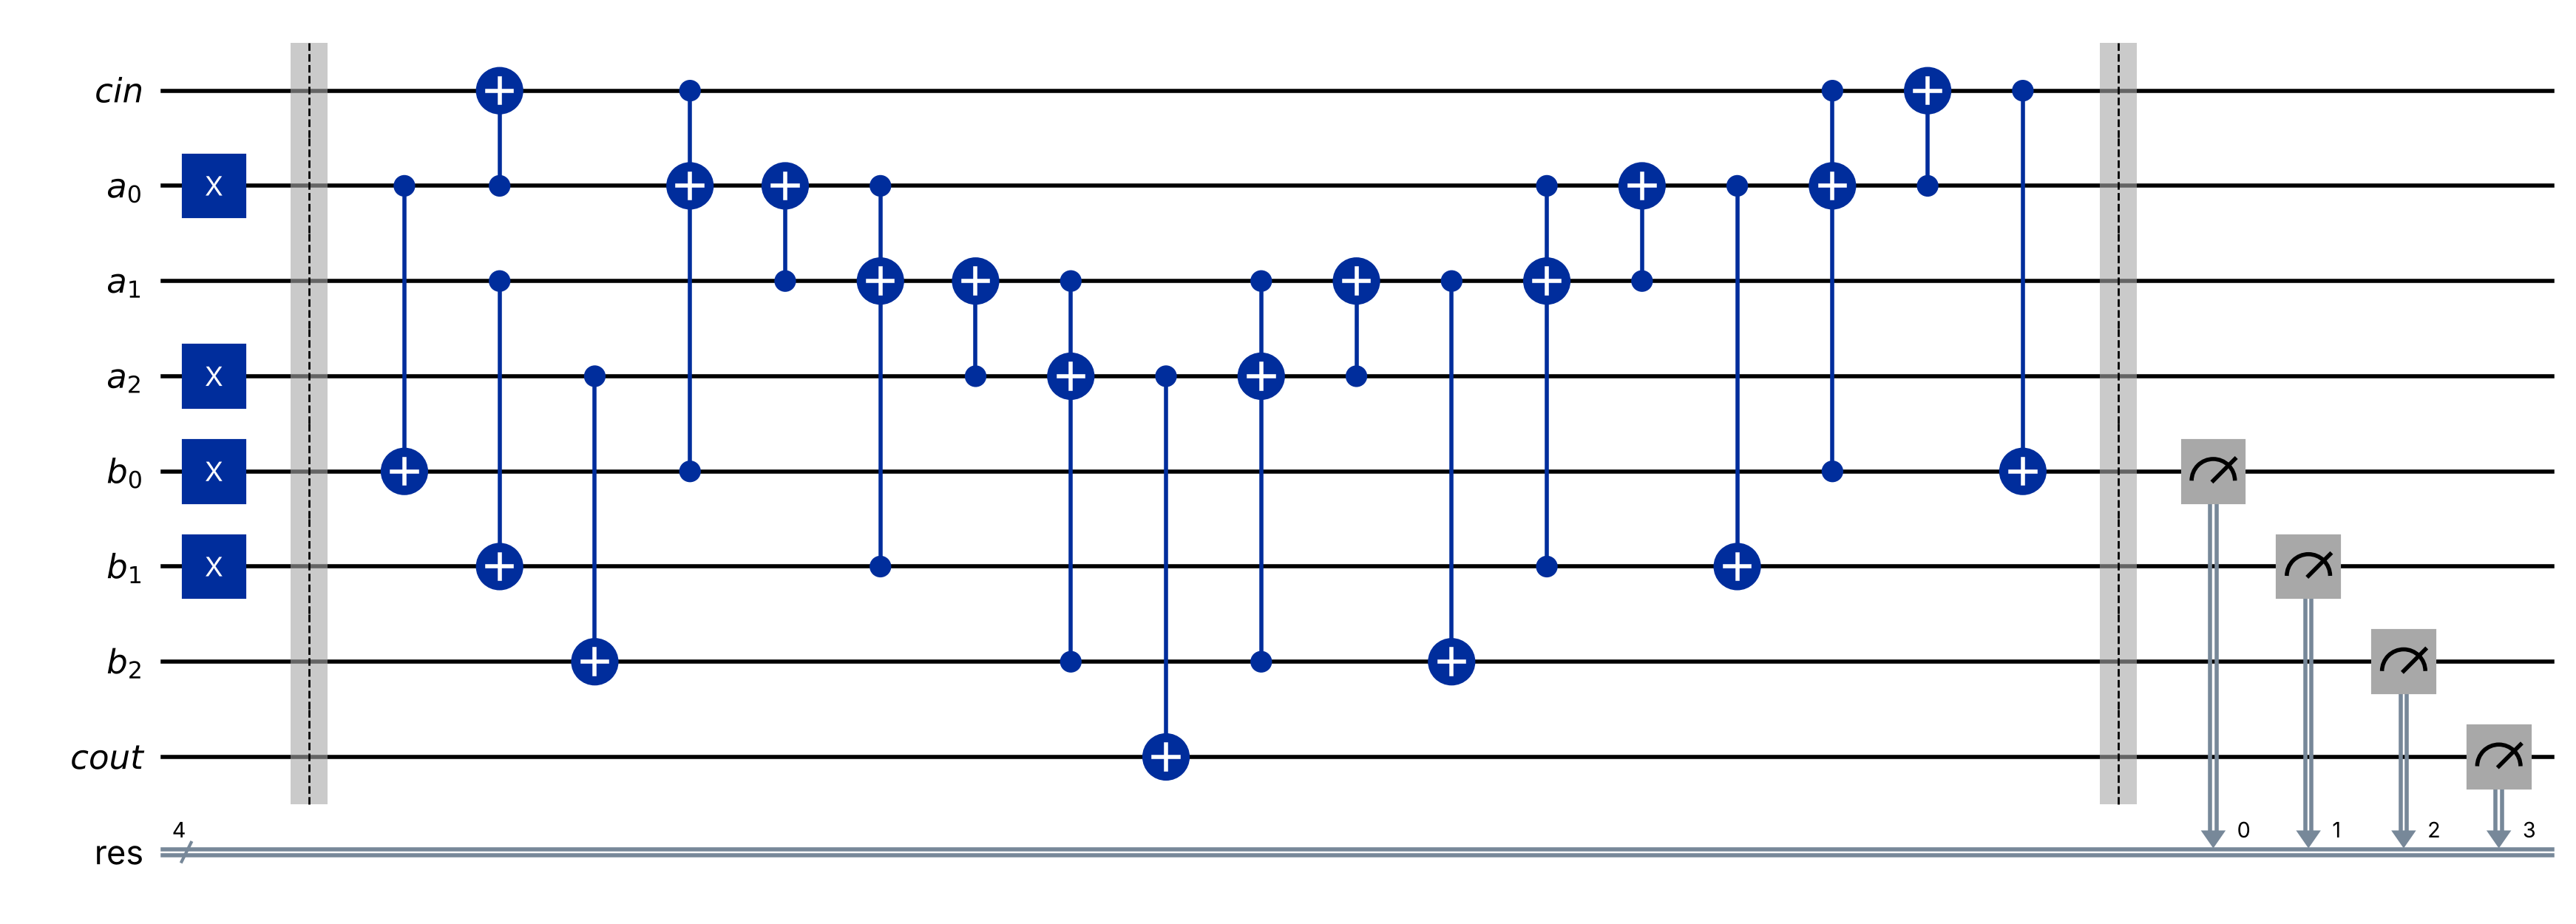

In [ ]:
from qiskit import qasm2
circuito = qasm2.load("qasm/suma_5mas3_cuccaro.qasm")   # el MISMO archivo que pegamos en el Composer
print("Compuertas del circuito original:", dict(circuito.count_ops()))
circuito.draw("mpl", fold=-1)

### Paso 1: traducir el circuito al chip

El chip no sabe hacer Toffoli ni CNOT directamente, y sus qubits no están todos conectados. Por eso, antes de
correr, Qiskit "transpila" el circuito. Lo hacemos aquí con `FakeKingston`, una copia que trae Qiskit de cómo es
ibm_kingston: sus compuertas, sus conexiones y los errores que IBM midió en él.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
from qiskit_ibm_runtime.fake_provider import FakeKingston

kingston = FakeKingston()
print("Compuertas nativas de ibm_kingston:", [g for g in kingston.operation_names if g in ("cz", "rz", "sx", "x")])

traducido = transpile(circuito, kingston, optimization_level=3, seed_transpiler=7)
def compuertas(c): return {k: v for k, v in c.count_ops().items() if k not in ("barrier", "measure")}
print("\nOriginal :", compuertas(circuito), "| profundidad", circuito.depth())
print("Traducido:", compuertas(traducido), "| profundidad", traducido.depth())
print("\nQubits físicos del chip que usó (de 156):", traducido.layout.final_index_layout())

Compuertas nativas de ibm_kingston: ['x', 'sx', 'rz', 'cz']

Original : {'cx': 13, 'ccx': 6, 'x': 4} | profundidad 19
Traducido: {'sx': 140, 'rz': 111, 'cz': 72, 'x': 7} | profundidad 220

Qubits físicos del chip que usó (de 156): [1, 0, 3, 16, 2, 4, 23, 5]


Las 13 CNOT y 6 Toffoli se convierten en unas **70 compuertas CZ** y más de 200 compuertas de un qubit. El circuito
queda **más de 10 veces más profundo**. Cada una de esas compuertas es una oportunidad más de error. (En el trabajo
real, IBM lo tradujo un poco distinto y le salieron 86 compuertas de dos qubits.)

### Paso 2: comparar los tres resultados

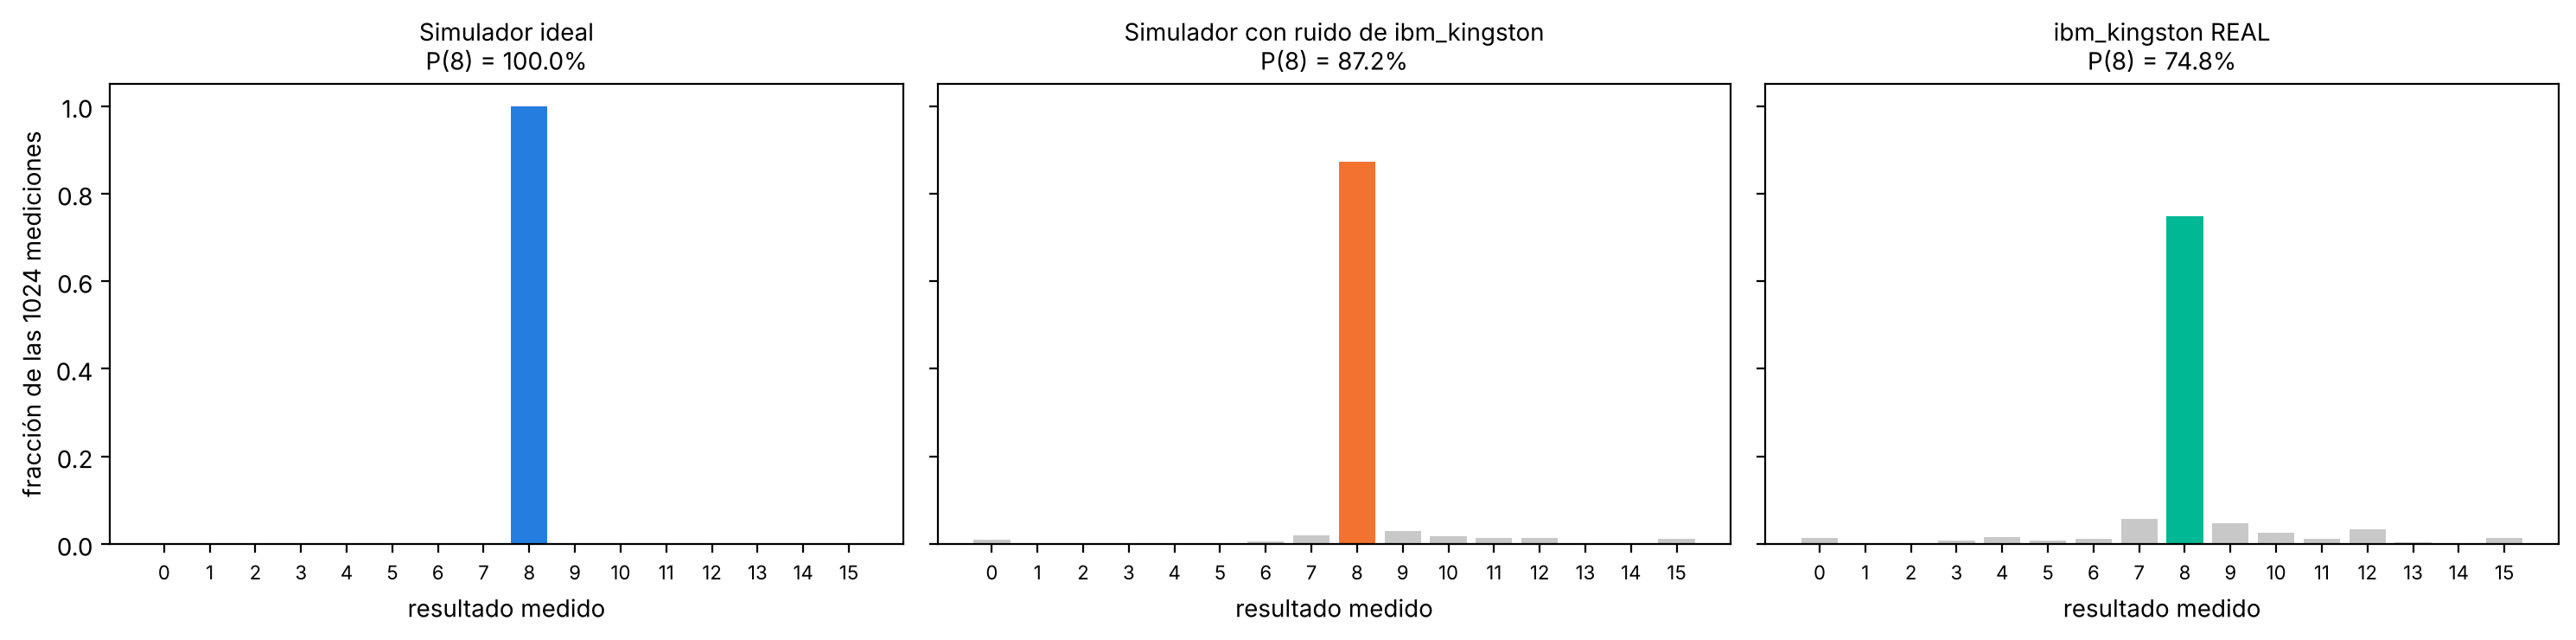

                                        P(resultado = 8)
Simulador ideal                                  100.0%
Simulador con ruido de ibm_kingston               87.2%
ibm_kingston REAL                                 74.8%


In [ ]:
import json

# 1) Simulación ideal (lo que corre en PowerShell)
ideal = AerSimulator(seed_simulator=7)
c_ideal = ideal.run(transpile(circuito, ideal), shots=1024).result().get_counts()

# 2) Simulación con el ruido medido de ibm_kingston
ruidoso = AerSimulator.from_backend(kingston, seed_simulator=7)
c_ruido = ruidoso.run(traducido, shots=1024).result().get_counts()

# 3) El computador cuántico REAL (resultado descargado de IBM)
real = json.load(open("resultados/ibm_kingston_5mas3_cuccaro.json"))
c_real = real["cuentas"]

valores = [format(v, "04b") for v in range(16)]
series = [("Simulador ideal", c_ideal, "#257de0"),
          ("Simulador con ruido de ibm_kingston", c_ruido, "#f47230"),
          ("ibm_kingston REAL", c_real, "#00b894")]

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (titulo, cuentas, color) in zip(axs, series):
    ys = [cuentas.get(v, 0) / 1024 for v in valores]
    ax.bar(range(16), ys, color=[color if v == "1000" else "#c8c8c8" for v in valores])
    ax.set_title(f"{titulo}\nP(8) = {cuentas.get('1000', 0) / 1024:.1%}", fontsize=10)
    ax.set_xticks(range(16), [str(i) for i in range(16)], fontsize=8)
    ax.set_xlabel("resultado medido")
axs[0].set_ylabel("fracción de las 1024 mediciones")
plt.tight_layout(); plt.show()

print(f"{'':38}{'P(resultado = 8)':>18}")
for titulo, cuentas, _ in series:
    print(f"{titulo:38}{cuentas.get('1000', 0) / 1024:>17.1%}")

**Qué vemos:**

* **Ideal:** siempre sale 8. Es matemática perfecta.
* **Con el ruido de ibm_kingston:** el 8 sigue ganando, pero aparecen otros valores con poca probabilidad.
* **Real:** el 8 sale el **74,8 %** de las veces. Es menos que en la simulación con ruido.

¿Por qué el real sale peor que la simulación con ruido? Algunas razones:

1. Los errores guardados en `FakeKingston` se midieron en una fecha anterior, y los errores de un chip real
   cambian de un día a otro.
2. IBM tradujo el circuito de otra forma (86 compuertas de dos qubits en vez de unas 70).
3. El modelo de ruido es una aproximación: no incluye todo lo que pasa en el chip, como la interferencia entre
   qubits vecinos.

Aun así, en los tres casos **la respuesta más frecuente es la correcta**. Con números más grandes eso ya no se
cumpliría: por eso los computadores cuánticos de hoy todavía necesitan **corrección de errores** para hacer
cálculos largos.

## 11. Conclusiones

* Sí se puede sumar y multiplicar con circuitos cuánticos, y nos dio bien en todos los casos que probamos.
* La parte que más tiene que ver con la materia es la QFT: sumar se convierte en multiplicar por raíces de la
  unidad, o sea, en rotar en el círculo unitario.
* No es más rápido que una calculadora normal. Estos circuitos sirven como piezas para algoritmos más grandes,
  como el de Shor.
* Lo corrimos en un computador cuántico real (ibm_kingston) y 5 + 3 dio 8 el 74,8 % de las veces. El ruido es un
  problema serio, sobre todo para la multiplicación.

**Referencias:** Draper (2000), arXiv:quant-ph/0008033 · Cuccaro et al. (2004), arXiv:quant-ph/0410184 ·
Ruiz-Pérez y García-Escartín (2017), arXiv:1411.5949 · Nielsen y Chuang, cap. 5 · documentación de Qiskit.